# Walkthrough: `08_sample_population.py` (PD Modeling Eligibility & Exclusions Audit)

### Simple Summary
**Before training a 12-month PD model, this script audits every row of the December `book_snapshot` and accounts for 100% of loans—separating clean `included` performing loans from valid exclusions (already in default, early masked balances, incomplete 2025 windows, or non-credit exits) so no selection bias hides.**

> **Safe "Look-But-Don't-Touch" Mode:** This notebook opens the fixed `0.03%` sample (`module2_sample.duckdb` and `book_snapshot/`) strictly **read-only in memory** without writing to disk.

---

### Process Flow
<div style="background:#FFFFFF;border:1px solid #CBD5E1;border-radius:8px;padding:14px;max-width:860px;">
<svg viewBox="0 0 820 200" width="100%" xmlns="http://www.w3.org/2000/svg" style="font-family:Segoe UI,Arial,sans-serif;">
  <defs>
    <marker id="arr" viewBox="0 0 10 10" refX="9" refY="5" markerWidth="7" markerHeight="7" orient="auto-start-reverse">
      <path d="M 0 1 L 10 5 L 0 9 z" fill="#64748B"/>
    </marker>
  </defs>
  <rect x="16" y="62" width="175" height="72" rx="6" fill="#051C2C"/>
  <text x="103" y="92" text-anchor="middle" fill="#FFFFFF" font-size="12.5" font-weight="bold">1. Scan Book Snapshot</text>
  <text x="103" y="112" text-anchor="middle" fill="#CBD5E1" font-size="10.5">All 26 December books</text>
  <line x1="191" y1="98" x2="216" y2="98" stroke="#64748B" stroke-width="1.8" marker-end="url(#arr)"/>
  <rect x="220" y="62" width="185" height="72" rx="6" fill="#1E3A8A"/>
  <text x="312" y="92" text-anchor="middle" fill="#FFFFFF" font-size="12.5" font-weight="bold">2. Bucket Exclusions</text>
  <text x="312" y="112" text-anchor="middle" fill="#DBEAFE" font-size="10.5">Defaulted, masked, 2025, etc.</text>
  <line x1="405" y1="98" x2="430" y2="98" stroke="#64748B" stroke-width="1.8" marker-end="url(#arr)"/>
  <rect x="434" y="62" width="180" height="72" rx="6" fill="#0E7C7B"/>
  <text x="524" y="92" text-anchor="middle" fill="#FFFFFF" font-size="12.5" font-weight="bold">3. Compare Risk Mix</text>
  <text x="524" y="112" text-anchor="middle" fill="#CCFBF1" font-size="10.5">FICO, LTV &amp; DTI by group</text>
  <line x1="614" y1="98" x2="639" y2="98" stroke="#64748B" stroke-width="1.8" marker-end="url(#arr)"/>
  <rect x="643" y="62" width="160" height="72" rx="6" fill="#051C2C"/>
  <text x="723" y="92" text-anchor="middle" fill="#FFFFFF" font-size="12.5" font-weight="bold">4. Waterfall Visual</text>
  <text x="723" y="112" text-anchor="middle" fill="#CBD5E1" font-size="10.5">Included vs. excluded share</text>
</svg>
</div>

---
### 1. Profiling Included vs. Excluded PD Observations (`sample_population_mart`)
A modeler must prove that exclusions did not accidentally drop high-risk loans. Here we attach `module2_sample.duckdb` (`READ_ONLY`), verify that `sample_population_mart` accounts for 100% of `book_snapshot` rows, and inspect mean FICO, LTV, and DTI across every inclusion/exclusion bucket.

In [1]:
# Load path, DuckDB, pandas, and matplotlib utilities
# Import libraries for read-only PD sample population verification
from pathlib import Path
import duckdb
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib.ticker as mtick

# Locate residential_mortgage/ root and attach module2_sample.duckdb strictly READ_ONLY
# Walk upward until reaching residential_mortgage/, then open an in-memory DuckDB connection
PACKAGE_ROOT = Path.cwd()
while PACKAGE_ROOT.name != "residential_mortgage" and PACKAGE_ROOT != PACKAGE_ROOT.parent:
    PACKAGE_ROOT = PACKAGE_ROOT.parent
if PACKAGE_ROOT.name != "residential_mortgage":
    PACKAGE_ROOT = Path(r"E:\Repos\V4_bank-credit-risk-platform\residential_mortgage")

FIXED_M2_DB = PACKAGE_ROOT / "00_data/processed/module_outputs/02_portfolio_analytics/sample/module2_sample.duckdb"
FIXED_SNAP_GLOB = (PACKAGE_ROOT / "00_data/processed/module_outputs/02_portfolio_analytics/sample/07_default_rate_history/book_snapshot/year=*/*.parquet").as_posix()
con = duckdb.connect(":memory:")
con.execute(f"ATTACH '{FIXED_M2_DB.as_posix()}' AS m2 (READ_ONLY)")

# Verify 100% row parity between sample_population_mart and book_snapshot and summarize groups
# Compare total snapshot row count against mart sum and aggregate mean FICO, LTV, and DTI by reason
snap_n = con.execute(f"SELECT count(*) FROM read_parquet('{FIXED_SNAP_GLOB}')").fetchone()[0]
mart_n = con.execute("SELECT sum(loans) FROM m2.sample_population_mart").fetchone()[0]
print(f"Row parity check: book_snapshot={snap_n:,} == sample_population_mart={mart_n:,} ({'PASS' if snap_n == mart_n else 'FAIL'})")

summary = con.execute("""
    SELECT population_group, reason, sum(loans)::BIGINT AS loans,
           round(100.0 * sum(loans) / sum(sum(loans)) OVER (), 2) AS share_pct,
           round(sum(mean_credit_score * loans) / NULLIF(sum(loans) FILTER (WHERE mean_credit_score IS NOT NULL), 0), 1) AS avg_fico,
           round(sum(mean_orig_ltv * loans) / NULLIF(sum(loans) FILTER (WHERE mean_orig_ltv IS NOT NULL), 0), 1) AS avg_ltv
    FROM m2.sample_population_mart
    GROUP BY 1, 2 ORDER BY loans DESC
""").fetchdf()
summary

Row parity check: book_snapshot=83,985 == sample_population_mart=83,985 (PASS)


,population_group,reason,loans,share_pct,avg_fico,avg_ltv
0,included,included_pd_sample,67026,79.81,747.0,69.4
1,excluded,masked_early_lt6m,6098,7.26,743.1,70.6
2,excluded,incomplete_window_2025,4682,5.57,759.0,70.7
3,excluded,unseasoned_lt6m,3586,4.27,756.5,71.2
4,excluded,in_default_at_snapshot,1342,1.60,680.8,75.9
5,excluded,missing_fico_or_dti,1216,1.45,730.6,66.8
6,excluded,non_credit_exit_before_12m,35,0.04,698.4,74.0


Every single observation (`100%`) is accounted for: `included_pd_sample` holds the clean performing loans, while `in_default_at_snapshot` clearly shows lower average FICO (confirming why defaulted loans belong in LGD/cure models rather than PD origination/performing training). Next, we visualize the inclusion breakdown over time.

---
### 2. Visualizing Included vs. Excluded Population Over Time
Plotting the yearly share of `included` vs. `excluded` observations makes structural exclusions obvious—such as the 2025 snapshot being 100% excluded because a full 12-month outcome window (`2026-12`) has not yet elapsed.

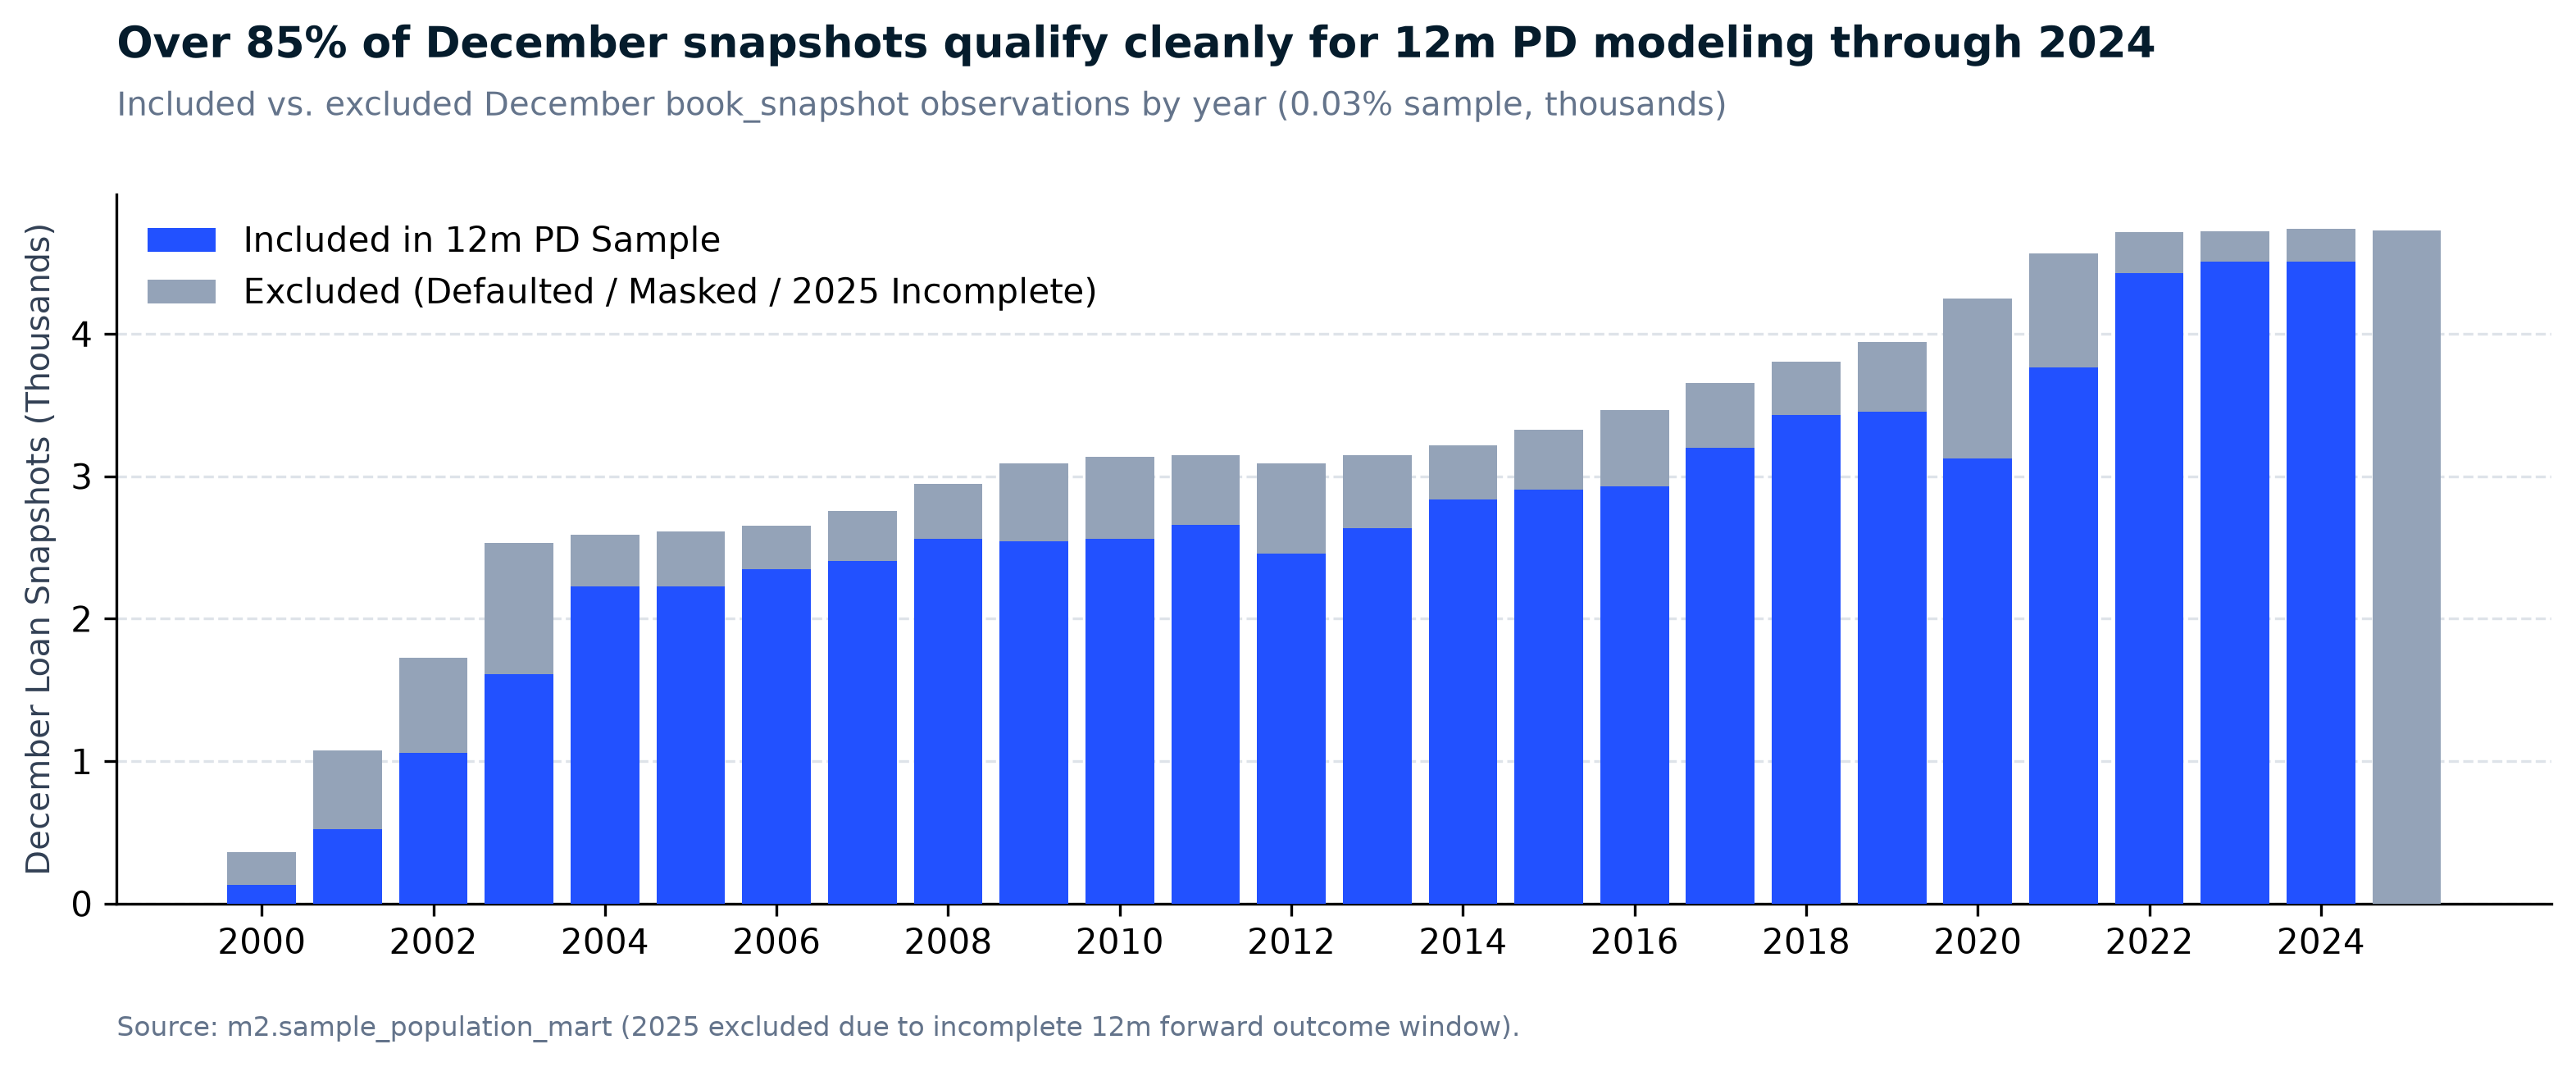

In [2]:
# Aggregate included vs. excluded loan counts by snapshot year and plot stacked bars at 300 dpi
# Query m2.sample_population_mart by snapshot_year and population_group and draw a clean stacked bar chart
yr_df = con.execute("""
    SELECT snapshot_year, population_group, sum(loans)::BIGINT AS loans
    FROM m2.sample_population_mart
    GROUP BY 1, 2 ORDER BY 1
""").fetchdf().pivot(index="snapshot_year", columns="population_group", values="loans").fillna(0)

fig, ax = plt.subplots(figsize=(11.0, 4.3), dpi=300, facecolor="#FFFFFF")
ax.set_facecolor("#FFFFFF")
yrs = yr_df.index.astype(int)
ax.bar(yrs, yr_df["included"] / 1e3, color="#2251FF", label="Included in 12m PD Sample", zorder=3)
ax.bar(yrs, yr_df["excluded"] / 1e3, bottom=yr_df["included"] / 1e3, color="#94A3B8", label="Excluded (Defaulted / Masked / 2025 Incomplete)", zorder=3)
ax.set_xticks(range(2000, 2026, 2))
ax.grid(axis="y", linestyle="--", alpha=0.3, color="#94A3B8", zorder=0)
ax.spines["top"].set_visible(False)
ax.spines["right"].set_visible(False)
ax.set_ylabel("December Loan Snapshots (Thousands)", fontsize=9.5, color="#334155")
ax.legend(frameon=False, loc="upper left")
fig.text(0.07, 0.94, "Over 85% of December snapshots qualify cleanly for 12m PD modeling through 2024", fontsize=12.5, fontweight="bold", color="#051C2C")
fig.text(0.07, 0.885, "Included vs. excluded December book_snapshot observations by year (0.03% sample, thousands)", fontsize=9.5, color="#64748B")
fig.text(0.07, 0.015, "Source: m2.sample_population_mart (2025 excluded due to incomplete 12m forward outcome window).", fontsize=8, color="#64748B")
plt.subplots_adjust(left=0.07, right=0.97, top=0.81, bottom=0.14)
plt.show()

# Close the in-memory DuckDB connection cleanly
# Release the attached read-only sample DB handle
con.close()

Every December snapshot from 2000 to 2024 supplies a clean performing modeling sample, while 2025 is cleanly held out for out-of-time scoring. Next, `09_risk_drivers.py` builds `t-1` behavioral features and ranks all origination and behavioral drivers by Information Value (IV).